
# Анализ дорожно-транспортных проишествий по Кировской и Московской областям

Заказчик проекта — «Карта ДТП». Это некоммерческий проект, посвящённый проблеме дорожно-транспортных происшествий в России. Цель проекта — повысить безопасность на дорогах.

«Карта ДТП» помогает выявлять реальные причины ДТП, оценивать уровень развития инфраструктуры, а также разрабатывать качественные решения и программы по повышению безопасности на улицах и дорогах. Заказчик хочет собирать данные более высокого качества и ожидает от вас рекомендаций: на какие проблемы или особенности обратить внимание.

Что нужно сделать
Проверить, встречаются ли в данных дубликаты и пропуски. Это поможет заказчикам собирать более качественные данные.

Ответить на следующие вопросы:
- как менялось число ДТП по временным промежуткам;
- различается ли число ДТП для групп водителей с разным стажем.

## Описание данных

Данные `Kirovskaya_oblast.csv`, `Moscowskaya_oblast.csv` содержат информацию ДТП:

* `geometry.coordinates` — координаты ДТП;

* `id` — идентификатор ДТП;

*  `properties.tags` — тег происшествия;

*  `properties.light` — освещённость;

*  `properties.point.lat` — широта;

*  `properties.point.long` — долгота;

*  `properties.nearby` — ближайшие объекты;

*  `properties.region` — регион;

*  `properties.scheme` — схема ДТП;

*  `properties.address` — ближайший адрес;

*  `properties.weather` — погода;

*  `properties.category` — категория ДТП;

*  `properties.datetime` — дата и время ДТП;

*  `properties.injured_count` — число пострадавших;

*  `properties.parent_region` — область;

*  `properties.road_conditions` — состояние покрытия;

*  `properties.participants_count` — число участников;

*  `properties.participant_categories` — категории участников.

`Moscowskaya_oblast_participiants.csv`, `Kirovskaya_oblast_participiants.csv` — сведения об участниках ДТП:

* `role` — роль;

* `gender` — пол;

* `violations` — какие правила дорожного движения были нарушены конкретным участником;

* `health_status` — состояние здоровья после  ДТП;

* `years_of_driving_experience` — число лет опыта;

* `id` — идентификатор ДТП.


`Kirovskaya_oblast_vehicles.csv`, `Moscowskaya_oblast_vehicles.csv` — сведения о транспортных средствах:

* `year` — год выпуска;

* `brand` — марка транспортного средства;

* `color` — цвет;

* `model` — модель;

* `category` — категория;

* `id` — идентификатор ДТП.

Загрузка библиотек и данных

In [247]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix

Датасет с информацией о ДТП по Кировской области и Московской области

In [248]:
df_k = pd.read_csv('https://code.s3.yandex.net/datasets/Kirovskaya_oblast.csv')
df_m = pd.read_csv('https://code.s3.yandex.net/datasets/Moscowskaya_oblast.csv')

Оптимизация назавания столбцов

In [249]:
df_k.columns = df_k.columns.str.replace('properties.', '')
df_k.columns = df_k.columns.str.replace('.', '_')

df_m.columns = df_m.columns.str.replace('properties.', '')
df_m.columns = df_m.columns.str.replace('.', '_')

df_new = pd.concat([df_k, df_m], axis= 0)

df_new.head(3)

,geometry_coordinates,id,tags,light,point_lat,point_long,nearby,region,scheme,address,weather,category,datetime,injured_count,parent_region,road_conditions,participants_count,participant_categories
0,"[47.875603, 57.24379]",1983180,Дорожно-транспортные происшествия,Светлое время суток,57.243790,47.875603,[],Яранский район,600.0,Р-176 Вятка Чебоксары - Йошкар-Ола - Киров - С...,['Дождь'],Опрокидывание,2017-07-01 18:00:00,1,Кировская область,['Мокрое'],3,['Все участники']
1,"[47.87903, 57.304807]",2889433,Дорожно-транспортные происшествия,Светлое время суток,57.304807,47.879030,"['Административные здания', 'Нерегулируемый пе...",Яранский район,710.0,"г Яранск, ул Кирова, 10",['Ясно'],Наезд на пешехода,2023-09-12 17:10:00,1,Кировская область,"['Сухое', 'Отсутствие, плохая различимость гор...",2,"['Все участники', 'Пешеходы']"
2,"[47.840781, 57.297156]",2591208,Дорожно-транспортные происшествия,Сумерки,57.297156,47.840781,"['Жилые дома индивидуальной застройки', 'Нерег...",Яранский район,NaN,"г Яранск, ул Чапаева, 80",['Пасмурно'],Съезд с дороги,2021-07-02 21:25:00,1,Кировская область,['Мокрое'],1,['Все участники']


Датасет с участниками ДТП в Кировской области и Московской области

In [250]:
df_obl_k = pd.read_csv('https://code.s3.yandex.net/datasets/Kirovskaya_oblast_participiants.csv')
df_obl_m = pd.read_csv('https://code.s3.yandex.net/datasets/Moscowskaya_oblast_participiants.csv')

In [251]:
df_obl_new = pd.concat([df_obl_k, df_obl_m], axis=0)

df_obl_new.head(3)

,role,gender,violations,health_status,years_of_driving_experience,id
0,Водитель,Мужской,['Несоответствие скорости конкретным условиям ...,"Раненый, находящийся (находившийся) на амбулат...",26.0,1983180
1,Водитель,Мужской,[],Не пострадал,34.0,2889433
2,Пассажир,Мужской,[],"Раненый, находящийся (находившийся) на амбула...",NaN,2591208


Датасет о транспотных средствах участников ДТП в Кировской области и Московской области

In [252]:
df_veh_k = pd.read_csv('https://code.s3.yandex.net/datasets/Kirovskaya_oblast_vehicles.csv')
df_veh_m = pd.read_csv('https://code.s3.yandex.net/datasets/Moscowskaya_oblast_vehicles.csv')

In [253]:
df_veh_new = pd.concat([df_veh_k, df_veh_m], axis=0)

df_veh_new.head(3)

,year,brand,color,model,category,id
0,2011.0,ВАЗ,Серый,Kalina,"А-класс (особо малый) до 3,5 м",1983180
1,2005.0,CHEVROLET,Зеленый,Niva,"С-класс (малый средний, компактный) до 4,3 м",2889433
2,2017.0,RENAULT,Синий,Logan,"С-класс (малый средний, компактный) до 4,3 м",2591208


### Проверка ошибок в данных и их предобработка


Пропуски в датасете df_new с информацией о ДТП

In [254]:
(pd.DataFrame({'Количество пропусков': df_new.isnull().sum(), 
               'Доля пропусков': df_new.isnull().mean().round(4), 
               'Количество дубликатов': df_new.duplicated().sum()}).style.background_gradient(cmap='coolwarm'))

,Количество пропусков,Доля пропусков,Количество дубликатов
geometry_coordinates,0,0.000000,0
id,0,0.000000,0
tags,0,0.000000,0
light,0,0.000000,0
point_lat,35,0.000600,0
point_long,35,0.000600,0
nearby,0,0.000000,0
region,0,0.000000,0
scheme,2520,0.041900,0
address,2430,0.040400,0


Больше всего пропусков в поле scheme не случайно, это связано со спецификой регистрации ДТП: схема ДТП составляется не всегда Пропуски в поле address также могут быть не случайными, так как ДТП происходят вне пределах города, где нет конкретного адреса point_lat и point_long, широта и долгота происшествия могут быть случайными или по неизвестным нам причинам

Пропуски в столбцах scheme и address возможно заменить на значение "нет данных" Пропуски в point_lat и point_long ввиду их малого количества можно оставить, если мы не будем строить геокарту

In [255]:
df_new[['scheme', 'address']] = df_new[['scheme', 'address']].fillna('нет данных')

Пропуски в датасете df_obl_new с информацией об участниках ДТП

In [256]:
(pd.DataFrame({'Количество пропусков': df_obl_new.isnull().sum(), 
               'Доля пропусков': df_obl_new.isnull().mean().round(4), 
               'Количество дубликатов': df_obl_new.duplicated().sum()}).style.background_gradient(cmap='coolwarm'))

,Количество пропусков,Доля пропусков,Количество дубликатов
role,0,0.000000,45155
gender,2718,0.021500,45155
violations,0,0.000000,45155
health_status,207,0.001600,45155
years_of_driving_experience,49824,0.394100,45155
id,0,0.000000,45155


39,4 % пропусков в поле years_of_driving_experience, лет вождения, что может говорить о водителях с отсутствующим стажем вождения. А может и нет. Пол водителя не указан в 2.2 % данных, что является случайным. Предполагается заменить на индикатор "нет данных" Состояние здоровья не указано в 0.2 %. Что может означать что здоровье осталось в норме после дтп. Однако это лишь предположение. Предполагается заменить на моду

В датасете df_obl_new обнаружено 35,7 % явных дубикатов. Удалим их.

In [257]:
df_obl_new['health_status'].mode()

0    Не пострадал
Name: health_status, dtype: object

In [258]:
df_obl_new['gender'] = df_obl_new['gender'].fillna('нет данных')
df_obl_new['health_status'] = df_obl_new['health_status'].fillna('Не пострадал')

df_obl_new = df_obl_new.drop_duplicates()

In [259]:
(pd.DataFrame({'Количество пропусков': df_obl_new.isnull().sum(), 
               'Доля пропусков': df_obl_new.isnull().mean().round(4), 
               'Количество дубликатов': df_obl_new.duplicated().sum()}).style.background_gradient(cmap='coolwarm'))

,Количество пропусков,Доля пропусков,Количество дубликатов
role,0,0.000000,0
gender,0,0.000000,0
violations,0,0.000000,0
health_status,0,0.000000,0
years_of_driving_experience,34962,0.430300,0
id,0,0.000000,0


Пропуски в столбце years_of_driving_experience оставим как есть. Они по видимому неслучайны, но об их наличии мы ничего не можем сказать на основе имеющихся данных

Пропуски в датасете df_veh_new с информацией о транспортных средствах

In [260]:
(pd.DataFrame({'Количество пропусков': df_veh_new.isnull().sum(), 
               'Доля пропусков': df_veh_new.isnull().mean().round(4), 
               'Количество дубликатов': df_veh_new.duplicated().sum()}).style.background_gradient(cmap='coolwarm'))

,Количество пропусков,Доля пропусков,Количество дубликатов
year,2540,0.029600,724
brand,2196,0.025600,724
color,1291,0.015100,724
model,2196,0.025600,724
category,0,0.000000,724
id,0,0.000000,724


Обнаруживаются пропуски в полях year 3% brand 2.6% model 2.6% color 1.5 %. Заменим их индикатором "нет данных"

In [261]:
df_veh_new[['year','brand', 'model', 'color']] = df_veh_new[['year', 'brand', 'model', 'color']].fillna('нет данных')

df_veh_new = df_veh_new.drop_duplicates()

In [262]:
(pd.DataFrame({'Количество пропусков': df_veh_new.isnull().sum(), 
               'Доля пропусков': df_veh_new.isnull().mean().round(4), 
               'Количество дубликатов': df_veh_new.duplicated().sum()}).style.background_gradient(cmap='coolwarm'))

,Количество пропусков,Доля пропусков,Количество дубликатов
year,0,0.000000,0
brand,0,0.000000,0
color,0,0.000000,0
model,0,0.000000,0
category,0,0.000000,0
id,0,0.000000,0


Объединим все данные в один датасет df_one

In [263]:
df_one = df_new.merge(df_obl_new, on='id', how='outer').merge(df_veh_new, on='id', how='outer')

df_one.head(3)

,geometry_coordinates,id,tags,light,point_lat,point_long,nearby,region,scheme,address,...,role,gender,violations,health_status,years_of_driving_experience,year,brand,color,model,category_y
0,"[47.886008, 57.30447]",1979481,Дорожно-транспортные происшествия,Светлое время суток,57.304470,47.886008,"['Многоквартирные жилые дома', 'Нерегулируемый...",Яранский район,740.0,"г Яранск, ул Кирова, 25",...,Водитель,Мужской,[],Не пострадал,26.0,2001.0,VOLKSWAGEN,Серый,Bora,"D-класс (средний) до 4,6 м"
1,"[47.886008, 57.30447]",1979481,Дорожно-транспортные происшествия,Светлое время суток,57.304470,47.886008,"['Многоквартирные жилые дома', 'Нерегулируемый...",Яранский район,740.0,"г Яранск, ул Кирова, 25",...,Пешеход,Женский,[],"Раненый, находящийся (находившийся) на амбула...",NaN,2001.0,VOLKSWAGEN,Серый,Bora,"D-класс (средний) до 4,6 м"
2,"[50.737665, 57.822582]",1979482,Дорожно-транспортные происшествия,Светлое время суток,57.822582,50.737665,['Жилые дома индивидуальной застройки'],Богородский район,610.0,"пгт Богородское, ул Советская, 97",...,Водитель,Мужской,['Нарушение правил расположения ТС на проезжей...,Не пострадал,NaN,2008.0,ЗИЛ,Синий,Прочие модели ЗИЛ,Прочая спецтехника


## Исследовательский анализ



### Какое число ДТП случилось в каждый день недели. Разбивка числа происшествий по месяцам

In [264]:
df_one['day_name'] = pd.to_datetime(df_one['datetime']).dt.day_name()

grouped_days_df = df_one.groupby('day_name')['id'].nunique().reset_index()
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

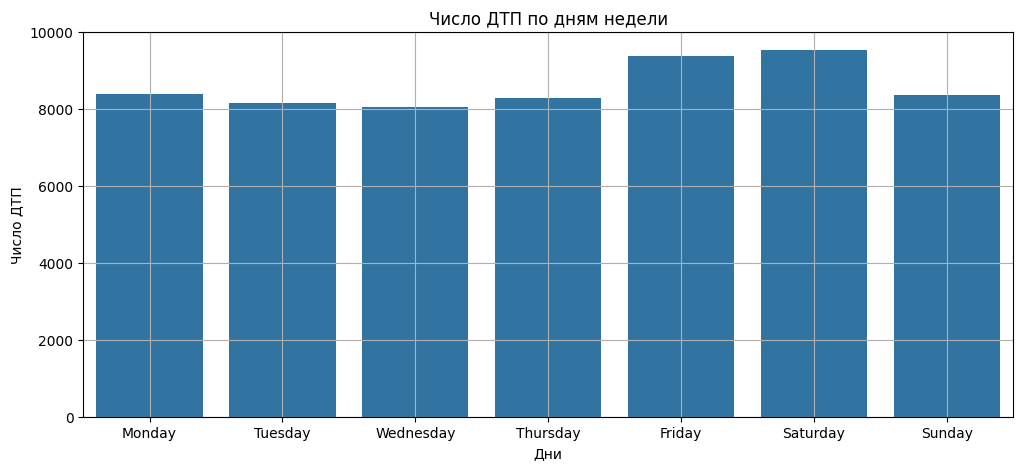

In [265]:
plt.figure(figsize=(12, 5))

ax= sns.barplot(x= 'day_name', y= 'id',data= grouped_days_df, order= days)

plt.title('Число ДТП по дням недели')
plt.ylabel('Число ДТП')
plt.xlabel('Дни')

plt.grid()
plt.show()

- ДТП случаются чаще в субботу и пятницу (15,8 % и 15,6 % от общенедельного числа)
- Реже всего по средам 13,4 %

In [266]:
df_one['month_name'] = pd.to_datetime(df_one['datetime']).dt.month_name()

grouped_month_df = df_one.groupby('month_name')['id'].nunique().reset_index()
month = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

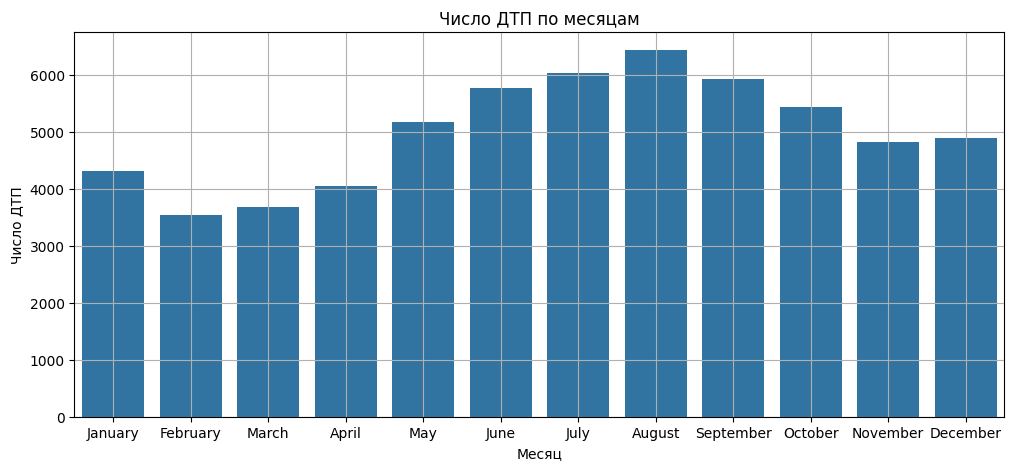

In [267]:
plt.figure(figsize=(12, 5))

ax= sns.barplot(x= 'month_name', y= 'id',data= grouped_month_df, order= month)

plt.title('Число ДТП по месяцам')
plt.ylabel('Число ДТП')
plt.xlabel('Месяц')

plt.grid()
plt.show()

- Маскимальное число случаев ДТП зарегистрировано в августе 10,7% от общегодового числа
- Минимум ДТП в феврале 5,9 %

### Категории водителей по стажу. Встречаются ли категории, которые разительно отличаются по числу ДТП

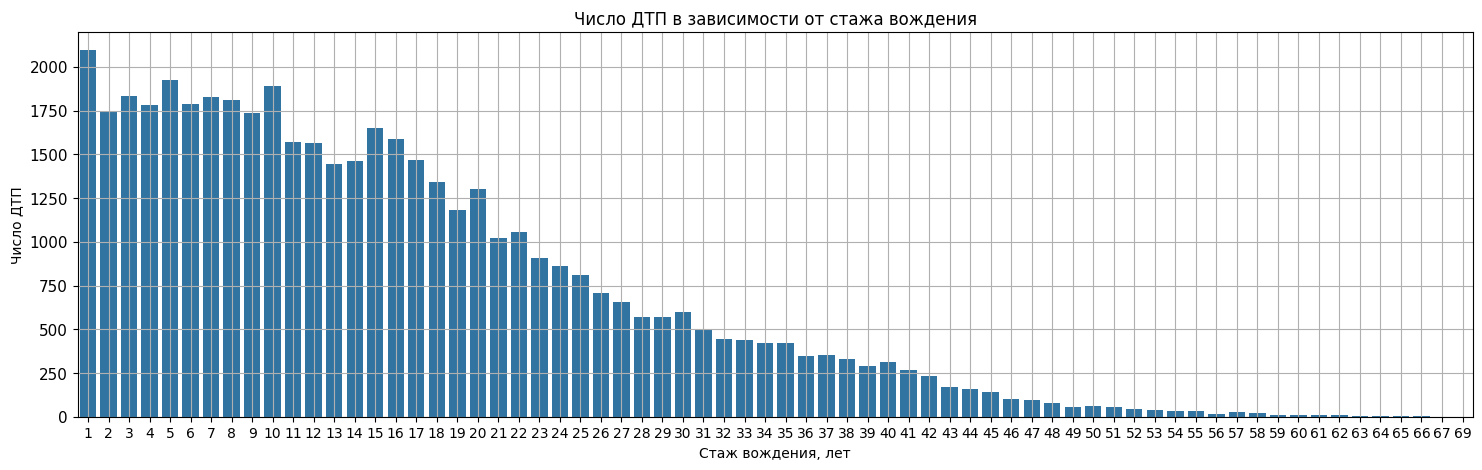

In [268]:
df_one['years_of_driving_experience'] = df_one['years_of_driving_experience'].astype('Int64')
df_group = df_one.groupby('years_of_driving_experience')['id'].nunique().reset_index()

plt.figure(figsize=(18, 5))

ax=sns.barplot(x= 'years_of_driving_experience', y= 'id',data= df_group)

plt.title('Число ДТП в зависимости от стажа вождения')
plt.ylabel('Число ДТП')
plt.xlabel('Стаж вождения, лет')

plt.yticks(fontsize=11)
plt.xticks(fontsize=10)

plt.grid()
plt.show()

- Диаграмма показывает, что в целом риск ДТП снижается с увеличением стажа вождения
- Нужно отметить также повышение риска ДТП при стаже 15-17 лет.

### Как менялось число аварий в Кировской (Киров входит в численность) и Московской области (Москва исключена). Где аварий больше в относительном выражении — в пересчёте на 100 тысяч жителей

Построим линейный график случаев ДТП с 2015 по 2024 годы для Кировской и Московской областей

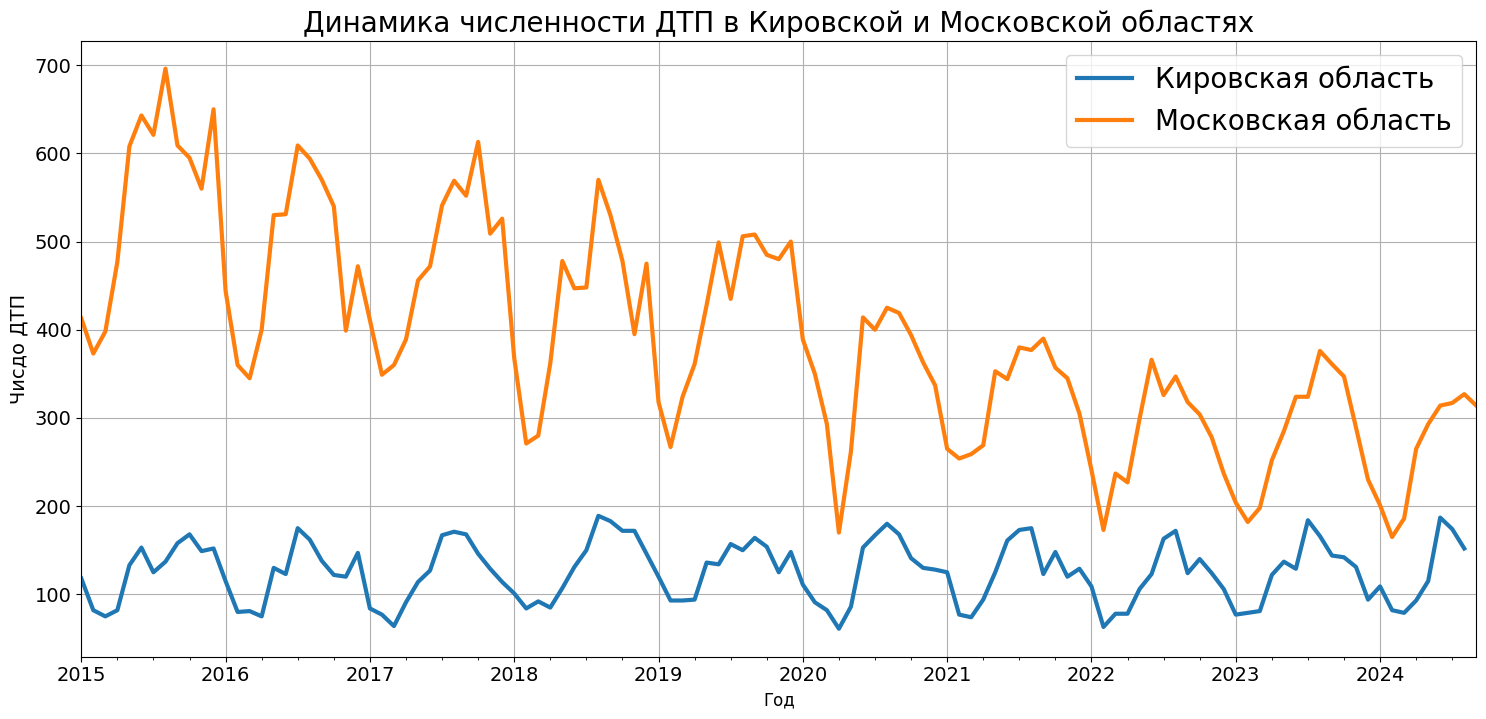

In [269]:
df_one['monthtime'] = pd.to_datetime(df_one['datetime']).dt.to_period('M')

plt.figure(figsize=(18, 8))

for i in df_one['parent_region'].unique():
    df_one[df_one['parent_region']== i].groupby('monthtime')['id'].nunique().plot(
    kind='line', x= 'monthtime', y='id',alpha=1, label=f'{i}', linewidth = 3, legend=True
    )

plt.title('Динамика численности ДТП в Кировской и Московской областях', fontsize = 20)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Чисдо ДТП', fontsize=14)

plt.gca().tick_params(labelsize=14)
plt.legend(fontsize=20)
plt.grid()
plt.show()

- Оба графика имеют волнообразный характер, с максимумами в середине года (июль, август) и минимумами в начале года (февраль, март)
- Численность ДТП в Московской области имеет четкую тенденцию на уменьшение со временем в пределах исследуемого периода.

Подсчет относительного числа ДТП на 100 тысяч населения для Кировской и Московской области

In [270]:
#Создадим столбец в датафрейме с годом ДТП
df_one['year_ra'] = pd.to_datetime(df_one['datetime']).dt.year

In [271]:
df_per_year = pd.DataFrame({'год': df_one['year_ra'].unique(), 
                              'дтп в кировской': df_one[df_one['parent_region']== 'Кировская область'].groupby('year_ra')['id'].nunique(),
                              'дтп в московской': df_one[df_one['parent_region']== 'Московская область'].groupby('year_ra')['id'].nunique(), 
                             })
df_per_year=df_per_year.set_index('год').sort_values(by='год')
df_per_year['puputation_kir']=[1304348, 1297474, 1291684, 1283238, 1272109, 1262402, 1153680, 1149176, 1138112, 1129935]
df_per_year['puputation_msk']=[7231068, 7318647, 7423470, 7503385, 7599647, 7690863, 8524665, 8542257, 8591736, 8651260]

def calculate_per_100k(value, population):
    result=(value/population)*100000
    return result
df_per_year['kir_per100k']=df_per_year.apply(lambda x: calculate_per_100k(x['дтп в кировской'],x['puputation_kir']), axis=1)
df_per_year['msk_per100k']=df_per_year.apply(lambda x: calculate_per_100k(x['дтп в московской'],x['puputation_msk']), axis=1)

df_per_year = df_per_year.reset_index() 

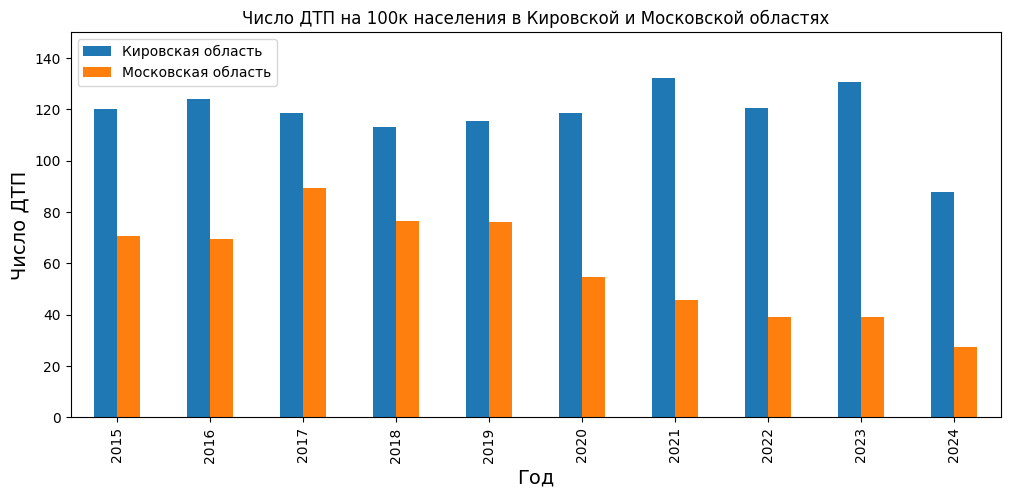

In [272]:
df_per_year.plot(kind= 'bar', x= 'год', y= ['kir_per100k', 'msk_per100k'], figsize=(12, 5))

plt.title('Число ДТП на 100к населения в Кировской и Московской областях')
plt.ylabel('Число ДТП', fontsize=14)
plt.xlabel('Год', fontsize=14)

plt.ylim(0,150)

plt.legend(['Кировская область','Московская область'])
plt.show()

- По относительным значениям случаев ДТП на 100 тысяч населения Кировская область в среднем примерно в 2 раза превосходит Московскую область.
- Минимальное число ДТП в Московской (27,9 на 100000) и Кировской (86,2 на 100000) области в 2022 году
- Максимальное для Московской области в 2017 году (89,5 на 100000), а для Кировской в 2024 году (132,6 на 100000)

# Итоговые выводы


В ходе исследования проанализировали данные 6 датасетов, 3-х по Кировской области и 3-х по Московской. Данные включали информацию о дорожно-транспортных происшествиях, участниках и транспортных средствах. Данные были объединены в 3 датасета включающих Кировскую и Московскую области, быта проведена обработка пропусков и дубликатов, оптимизация типов данных и названий столбцов. В результате всю информацию собрали в единый датасет для дальнейшего анализа.

Анализ числа ДТП в разрезе дня недели выявил, что:
- ДТП случаются чаще в субботу и пятницу (15,8 % и 15,6 % от общенедельного числа, соответственно)
- Реже всего по средам 13,4 %

Анализ числа ДТП по месяцам показал:
- Маскимальное число случаев ДТП зарегистрировано в августе 10,7% от общегодового числа
- Минимум ДТП в феврале 5,9 %

В исследовании зависимости числа ДТП от стажа вождения:
- Водители с минимальным стажем 1 год имеют повышенный риск ДТП 2,6 %, что вполне очевидно ввиду неопытности.
- Однако интересно, что за ними следуют водители со стажем 5 (2,4%) и 10 (2,3%) лет,
- а водители со стажем 2 года (2,15%) находятся на 9 месте по числу ДТП.
- в целом риск ДТП снижается с увеличением стажа вождения
- Нужно отметить также повышение риска ДТП при стаже 15-17 лет.

Анализ динамики численности ДТП в Кировской и Московской областях
- Количество ДТП имеют волнообразный характер, с максимумами в середине года (июль, август) и минимумами в начале года (февраль, март)
- Численность ДТП в Московской области имеет четкую тенденцию на уменьшение со временем в пределах исследуемого периода.
- По относительным значениям случаев ДТП на 100 тысяч населения Кировская область в среднем примерно в 2 раза превосходит Московскую область.
- Минимальное число ДТП в Московской (27,9 на 100000) и Кировской (86,2 на 100000) области в 2022 году
- Максимальное для Московской области в 2017 году (89,5 на 100000), а для Кировской в 2024 году (132,6 на 100000).

Повышенный риск случаев ДТП по субботам и пятницам, в августе и июле. В Кировской области, в отличие от Московской число ДТП не снижается со временем. Стоит обратить внимание на водителей со стажем 5 и 10 лет имеющих высокий риск ДТП.